# 02 — Phân cụm người chơi theo phong cách thi đấu

Mục tiêu: tạo hồ sơ người chơi từ các chỉ số theo round, chọn số cụm, diễn giải cụm và kiểm tra độ ổn định.

Đơn vị phân tích: **một PlayerID**.


In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from valorant_mining.config import DATA_PROCESSED, MODEL_FEATURES
from valorant_mining.clustering import run_clustering, save_clustering
from valorant_mining.plotting import plot_clustering

players = pd.read_csv(DATA_PROCESSED / "player_features.csv")
attrition = pd.read_csv(DATA_PROCESSED / "player_attrition.csv")
display(attrition)
players[MODEL_FEATURES].describe().T


,step,players
0,Người chơi trong bảng điểm sạch,7481
1,Đủ ≥10 ván,2725
2,Đủ ≥100 round,2725
3,Độ phủ ACS/ADR/HS ≥80%,2599
4,Đủ biến mô hình,2599


,count,mean,std,min,25%,50%,75%,max
kills_pr,2599.0,0.695771,0.091087,0.412921,0.632902,0.690765,0.752891,1.123348
deaths_pr,2599.0,0.714500,0.049891,0.552189,0.679904,0.713805,0.746463,0.885246
assists_pr,2599.0,0.251861,0.058304,0.105263,0.210859,0.246172,0.288164,0.478386
kd,2599.0,0.979736,0.151662,0.527473,0.879360,0.977612,1.077050,1.613924
acs,2599.0,200.698556,25.127466,119.289474,183.003914,199.488539,216.713049,315.149780
adr,2599.0,129.937172,15.031382,85.349624,119.694961,129.457286,139.790429,186.831288
fk_pr,2599.0,0.097470,0.040403,0.018462,0.067826,0.087237,0.120078,0.278783
fd_pr,2599.0,0.099371,0.033355,0.014815,0.074443,0.094340,0.120971,0.256098
multi_pr,2599.0,0.169302,0.033805,0.071429,0.145468,0.167364,0.190444,0.312775
acs_sd,2599.0,56.070133,10.576259,22.092985,49.527013,55.386454,62.300891,114.983667


## 1. Chạy K-Means và chọn k

Trước K-Means, các biến được winsorize 1%–99%, chuẩn hóa và **giảm chiều bằng PCA** giữ ≥80% phương sai. Cách này hạn chế việc nhóm biến combat tương quan mạnh (Kills/round, ACS, ADR, K/D, multi-kill) chi phối khoảng cách.

Silhouette được tính cho k = 2..8 trên không gian PCA. Vì mục tiêu là 3–5 nhóm có thể diễn giải, `choose_k` chỉ chọn trong khoảng 3–5; silhouette toàn miền vẫn được báo cáo để so sánh.


In [2]:
result = run_clustering(players)
display(result["high_correlation"])
display(result["sensitivity"])
result["evaluation"][["k", "inertia", "silhouette", "calinski_harabasz", "davies_bouldin"]]


,feature_a,feature_b,correlation,abs_correlation
1,kills_pr,acs,0.972,0.972
8,acs,adr,0.954,0.954
4,kills_pr,multi_pr,0.935,0.935
2,kills_pr,adr,0.921,0.921
10,acs,multi_pr,0.917,0.917
0,kills_pr,kd,0.894,0.894
11,adr,multi_pr,0.871,0.871
5,kd,acs,0.826,0.826
6,kd,adr,0.807,0.807
7,kd,multi_pr,0.805,0.805


,method,n_features,silhouette,ari_vs_primary,cluster_sizes,silhouette_space
0,PCA 0.8,3,0.278424,1.000000,"[760, 849, 990]",PCA
1,11 biến gốc,11,0.207080,0.968419,"[846, 742, 1011]",raw features
2,7 biến rút gọn,7,0.190635,0.473253,"[1029, 800, 770]",raw features


,k,inertia,silhouette,calinski_harabasz,davies_bouldin
0,2,13723.637439,0.358215,1845.842696,1.071577
1,3,10663.599403,0.278717,1559.789786,1.187789
2,4,8905.309870,0.271022,1415.492068,1.127448
3,5,7725.440555,0.255336,1322.306183,1.154445
4,6,7031.774810,0.239283,1212.913128,1.145309
5,7,6433.199859,0.233373,1144.578997,1.186699
6,8,5972.089305,0.229662,1084.988164,1.171456


In [3]:
print(result["summary"])
display(result["raw_profiles"].round(3))
display(result["z_profiles"][["n_players", "top_features", "low_features"]])


{'k': 3, 'best_silhouette_k': 2, 'best_silhouette': 0.35821460112382003, 'silhouette': 0.2784235448092689, 'stability_mean_ari': np.float64(0.9535249274376196), 'stability_min_ari': 0.866372832370585, 'ward_ari': 0.35422722751430696, 'ward_silhouette': 0.2151665747827192, 'pca_components': 3, 'pca_variance': 0.8212175580317365, 'visualization_variance': 0.7264548736107967, 'n_players': 2599, 'cluster_sizes': {0: 760, 1: 849, 2: 990}, 'cluster_labels': {0: 'Mở giao tranh · Sát thương cao', 1: 'Chết nhiều · Hiệu quả thấp', 2: 'Ít chết · Hiệu quả cao'}, 'feature_variance': {'kills_pr': 0.0079, 'deaths_pr': 0.0024, 'assists_pr': 0.0033, 'kd': 0.0221, 'acs': 603.6667, 'adr': 217.2787, 'fk_pr': 0.0016, 'fd_pr': 0.0011, 'multi_pr': 0.0011, 'acs_sd': 104.3641, 'hs': 0.0018}}


,kills_pr,deaths_pr,assists_pr,kd,acs,adr,fk_pr,fd_pr,multi_pr,acs_sd,hs,n_players,role_duelist_share,role_initiator_share,role_controller_share,role_sentinel_share,role_other_share,win_rate,cluster_label
cluster,,,,,,,,,,,,,,,,,,,
0,0.792,0.731,0.214,1.090,228.347,144.894,0.146,0.129,0.205,64.067,0.236,760,0.690,0.106,0.088,0.117,0.0,0.486,Mở giao tranh · Sát thương cao
1,0.602,0.736,0.255,0.822,175.728,115.114,0.072,0.096,0.137,49.761,0.226,849,0.136,0.305,0.288,0.270,0.0,0.376,Chết nhiều · Hiệu quả thấp
2,0.702,0.684,0.278,1.030,200.888,131.167,0.082,0.080,0.170,55.342,0.237,990,0.124,0.321,0.282,0.273,0.0,0.526,Ít chết · Hiệu quả cao


,n_players,top_features,low_features
cluster,,,
0,760,"First kills / round, ACS, Kills / round","Assists / round, HS %"
1,849,"Deaths / round, Assists / round, First deaths ...","K/D, Kills / round"
2,990,"Assists / round, K/D, HS %","Deaths / round, First deaths / round"


## 2. Hình minh họa

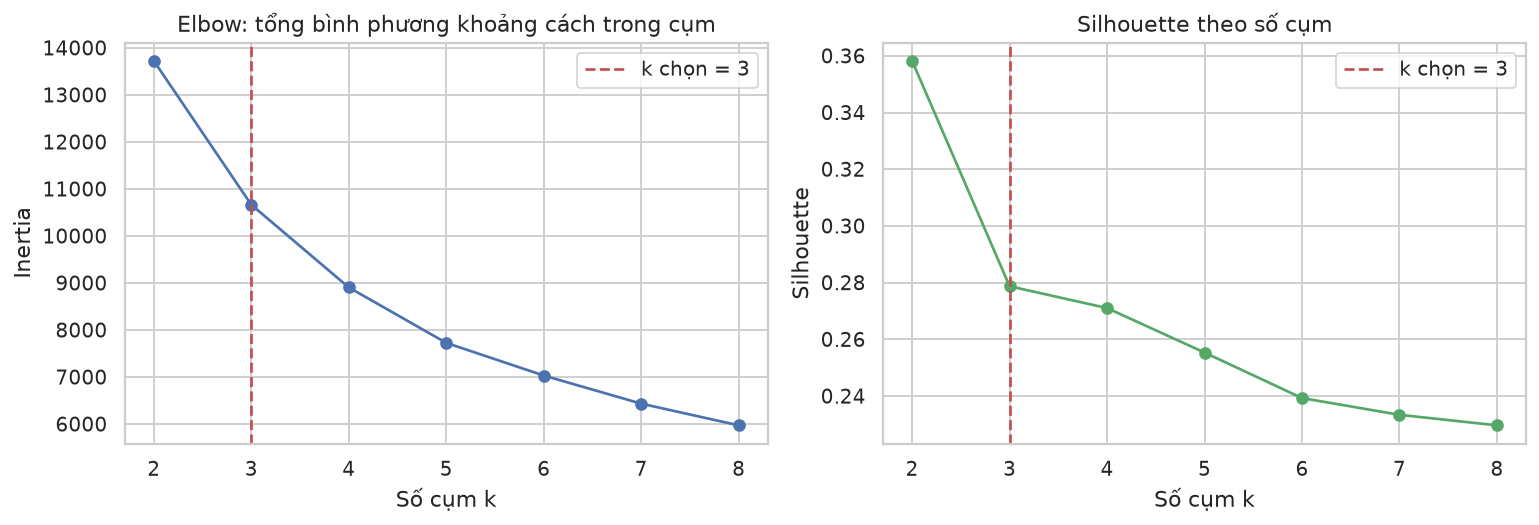

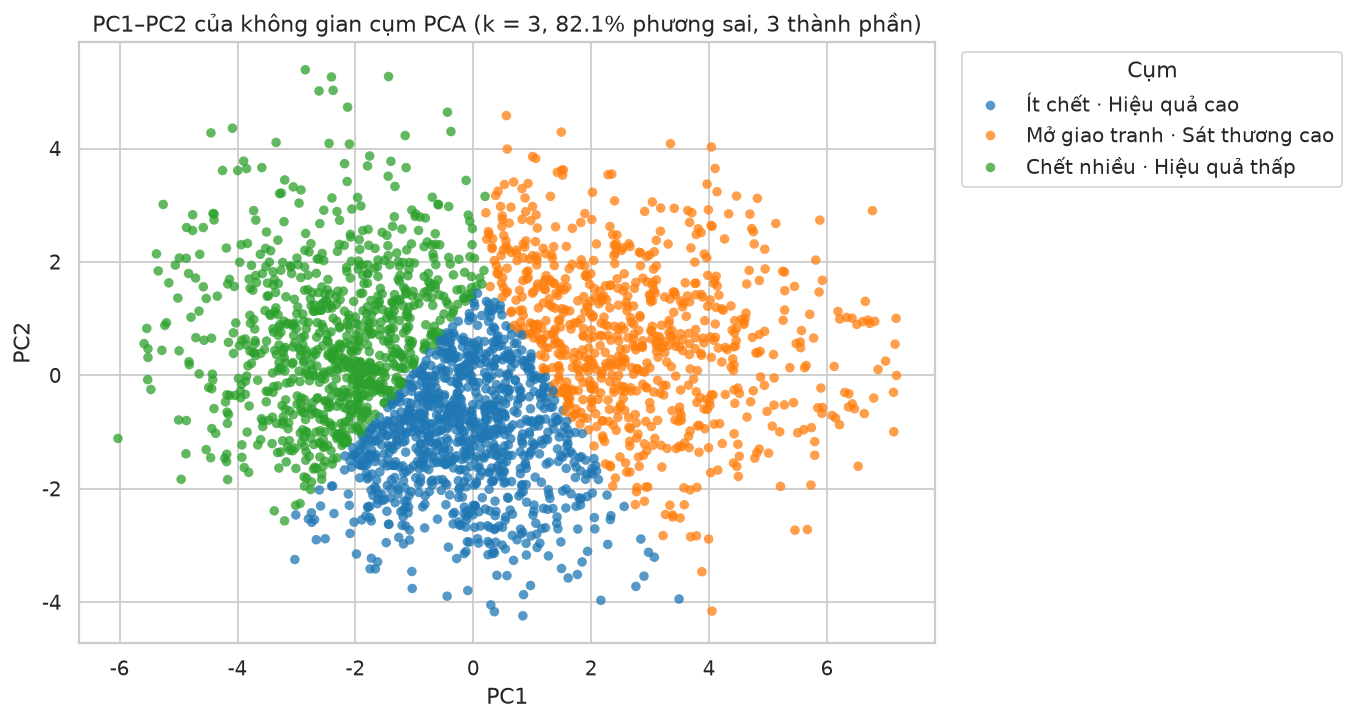

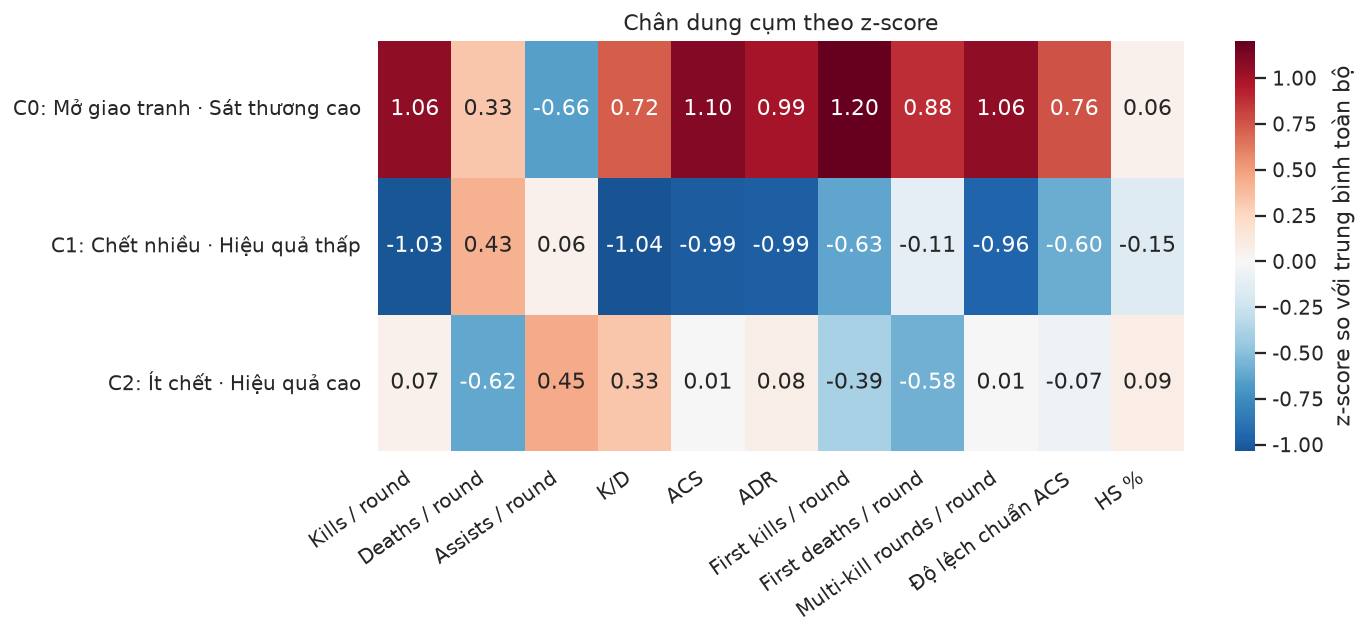

In [4]:
save_clustering(result)
plot_clustering(result)
for name in ["02_cluster_selection.png", "02_cluster_pca.png", "02_cluster_profiles.png"]:
    display(Image(filename=str(ROOT / "reports" / "figures" / name)))


## 3. Cách đọc kết quả

- **C0** có First kills/round, ACS và Kills/round cao nhất → nhóm mở giao tranh/sát thương.
- **C1** có K/D, ACS thấp và Deaths/round cao → nhóm chết nhiều, hiệu quả thấp.
- **C2** có K/D, assists và HS% cao, deaths thấp → nhóm ít chết, hiệu quả cao.

Lưu ý về độ tin cậy:

- Silhouette cao nhất ở k = 2, nhưng k = 3 được chọn để có ba nhóm diễn giải được trong khung 3–5 cụm. Đây là lựa chọn khám phá, không phải k tối ưu tuyệt đối.
- Bootstrap ARI cao (≈0,95) nhưng Ward chỉ đồng thuận một phần (ARI ≈0,35), nên cấu trúc cụm phụ thuộc thuật toán.
- K-Means trên 11 biến gốc cho kết quả gần với PCA (ARI ≈0,97), nhưng bộ 7 biến rút gọn thay đổi nhiều hơn (ARI ≈0,47). Ba cụm không phải cấu trúc duy nhất.
- C0 dùng Agent Duelist ở phần lớn số ván. Vì vậy cụm phản ánh cả **vai trò Agent** lẫn phong cách; không nên gọi cụm là “Duelist” hay “IGL” như một kết luận.
